In [1]:
!pip install -q ultralytics
import os, pandas as pd, numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

inp = Path("/kaggle/input")
best = next(inp.rglob("best.pt")); print("Model:", best)
per_pat = pd.read_csv(next(inp.rglob("nlm_per_patient.csv")), index_col=0)
ann = pd.read_csv(next(inp.rglob("nlm_annotations.csv")))
print(per_pat.split.value_counts())

os.makedirs("/tmp/nlm", exist_ok=True)
!wget -q --show-progress https://data.lhncbc.nlm.nih.gov/public/Malaria/Thick_Smears_150/ThickBloodSmears_150.zip -O /tmp/nlm/thick150.zip
!unzip -q -o /tmp/nlm/thick150.zip -d /tmp/nlm/data && rm /tmp/nlm/thick150.zip

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 5.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model: /kaggle/input/notebooks/divinembah/02-train-yolo-nlm/runs/nlm_y11s/weights/best.pt
split
train    99
test     30
val      21
Name: count, dtype: int64
/tmp/nlm/thick150.z 100%[===================>]   3.65G   294MB/s    in 11s     


In [2]:
model = YOLO(str(best))
data = Path("/tmp/nlm/data")
todo = ann.loc[ann.patient.isin(per_pat.index[per_pat.split.isin(["val", "test"])]), ["patient", "image"]].drop_duplicates()

rows = []
for i, (pat, stem) in enumerate(todo.itertuples(index=False)):
    im = Image.open(data / pat / f"{stem}.jpg").convert("RGB")            
    im = im.resize((im.width // 2, im.height // 2), Image.BILINEAR)   
    b = model.predict(im, imgsz=2016, conf=0.05, max_det=3000, device=0, verbose=False)[0].boxes
    for (x1, y1, x2, y2), c, k in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()):
        rows.append((pat, stem, int(k), float(c), (x1 + x2) / 2, (y1 + y2) / 2))
    if i % 100 == 0: print(i, "/", len(todo))

det = pd.DataFrame(rows, columns=["patient", "image", "cls", "conf", "x", "y"])
det.to_csv("/kaggle/working/nlm_detections_valtest.csv", index=False)
print(len(det), "detections on", len(todo), "photos")

0 / 648
100 / 648
200 / 648
300 / 648
400 / 648
500 / 648
600 / 648
73766 detections on 648 photos


In [3]:
def patient_counts(d, t_par, t_wbc=0.25):
    d = d[((d.cls == 0) & (d.conf >= t_par)) | ((d.cls == 1) & (d.conf >= t_wbc))]
    c = d.groupby(["patient", "cls"]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
    c.columns = ["pred_par", "pred_wbc"]
    c = c.join(per_pat[["Parasite", "White_Blood_Cell", "density_per_uL"]])
    c["pred_density"] = c.pred_par.clip(lower=0.5) / c.pred_wbc * 8000
    c["ratio"] = c.pred_density / c.density_per_uL
    return c

val_p = per_pat.index[per_pat.split == "val"]
rows = []
for t in np.round(np.arange(0.10, 0.71, 0.05), 2):
    c = patient_counts(det[det.patient.isin(val_p)], t)
    lr = np.log10(c.ratio)
    rows.append((t, round(10 ** lr.mean(), 3), round(np.median(np.abs(c.ratio - 1)) * 100, 1)))
tab = pd.DataFrame(rows, columns=["threshold", "typical_ratio (1=unbiased)", "median_abs_%_error"])
print(tab.to_string(index=False))
T_PAR = tab.loc[tab["median_abs_%_error"].idxmin(), "threshold"]
print("\nChosen parasite cut-off (from val only):", T_PAR)

 threshold  typical_ratio (1=unbiased)  median_abs_%_error
      0.10                       1.550                50.1
      0.15                       1.204                22.2
      0.20                       1.049                12.7
      0.25                       0.949                 8.3
      0.30                       0.870                 8.5
      0.35                       0.789                15.9
      0.40                       0.708                23.5
      0.45                       0.621                34.6
      0.50                       0.505                44.8
      0.55                       0.356                64.9
      0.60                       0.186                76.6
      0.65                       0.044                94.3
      0.70                       0.005                99.3

Chosen parasite cut-off (from val only): 0.25


In [4]:
c = patient_counts(det[det.patient.isin(per_pat.index[per_pat.split == "test"])], T_PAR)

def stats(df):
    return (10 ** np.log10(df.ratio).mean(),                    
            np.median(np.abs(df.ratio - 1)) * 100,           
            (np.abs(df.ratio - 1) <= 0.25).mean() * 100)       
est = stats(c)
B = np.array([stats(c.sample(len(c), replace=True, random_state=i)) for i in range(2000)])
lo, hi = np.percentile(B, [2.5, 97.5], axis=0)
for n, e, l, h in zip(["Typical ratio (1 = unbiased)", "Median absolute % error", "% patients within ±25%"], est, lo, hi):
    print(f"{n}: {e:.2f}  (95% CI {l:.2f} to {h:.2f})")

lr = np.log10(c.ratio)
print("Agreement limits (95% of patients fall between):", round(10 ** (lr.mean() - 1.96 * lr.std()), 2),
      "x and", round(10 ** (lr.mean() + 1.96 * lr.std()), 2), "x the true density")

bands, names = [0, 1000, 10000, 100000, np.inf], ["<1k", "1k-10k", "10k-100k", ">100k"]
c["true_band"] = pd.cut(c.density_per_uL, bands, labels=names); c["pred_band"] = pd.cut(c.pred_density, bands, labels=names)
print("\n", pd.crosstab(c.true_band, c.pred_band, rownames=["true"], colnames=["predicted"]))
print("Same density band:", round((c.true_band == c.pred_band).mean() * 100), "% of patients")
print("\n", c[["Parasite", "pred_par", "White_Blood_Cell", "pred_wbc", "density_per_uL", "pred_density", "ratio"]]
      .round(2).sort_values("density_per_uL").to_string())
c.to_csv("/kaggle/working/nlm_test_patient_density.csv")

Typical ratio (1 = unbiased): 0.91  (95% CI 0.83 to 0.99)
Median absolute % error: 12.19  (95% CI 6.94 to 15.56)
% patients within ±25%: 80.00  (95% CI 66.58 to 93.33)
Agreement limits (95% of patients fall between): 0.56 x and 1.49 x the true density

 predicted  <1k  1k-10k  10k-100k  >100k
true                                   
1k-10k       1      15         0      0
10k-100k     0       2        11      0
>100k        0       0         0      1
Same density band: 90 % of patients

               Parasite  pred_par  White_Blood_Cell  pred_wbc  density_per_uL  pred_density  ratio
patient                                                                                          
TF90_15_60          35        13               238       238         1176.47        436.97   0.37
TF118_1532          58        48               311       313         1491.96       1226.84   0.82
TF25_15_1_52        45        50               226       222         1592.92       1801.80   1.13
TF46_UW23         

In [5]:
import yaml
def make_yaml(folder, out):
    src = next(p for p in inp.rglob(folder) if p.is_dir())
    yaml.safe_dump({"path": str(src), "train": "test/images", "val": "test/images", "test": "test/images",
                    "names": {0: "parasite", 1: "wbc"}}, open(out, "w"))
    return src
bd_dir = make_yaml("nlm_tiles", "/kaggle/working/bd.yaml")
tz_dir = make_yaml("tz_tiles", "/kaggle/working/tz.yaml")

res = {}
for site, y in [("Bangladesh (test patients)", "/kaggle/working/bd.yaml"), ("Tanzania", "/kaggle/working/tz.yaml")]:
    m = model.val(data=y, split="test", imgsz=640, batch=32, device=0, plots=False, verbose=False)
    res[site] = {"parasite precision": m.box.p[0], "parasite recall": m.box.r[0],
                 "parasite mAP50": m.box.ap50[0], "wbc mAP50": m.box.ap50[1]}
print(pd.DataFrame(res).T.round(3))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.0 ms, read: 0.5±0.1 MB/s, size: 64.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/notebooks/divinembah/01-explore-nlm-thick/nlm_tiles/test/labels... 2845 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2845/2845 12.4it/s 3:500.2ss
WARNING ⚠️ val: Cache directory /kaggle/input/notebooks/divinembah/01-explore-nlm-thick/nlm_tiles/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 89/89 2.6s/it 3:512.4ss
                   all       2845      37096      0.924      0.906      0.938      0.496
Speed: 0.7ms preprocess, 11.0ms inference, 0.0ms loss, 0.8

In [6]:
def summarise(pred, true, name):
    d = pd.DataFrame({"pred": pred, "true": true}).fillna(0)
    d = d[d.true > 0]; r = d.pred / d.true
    print(f"{name}: {len(d)} photos | median count ratio {r.median():.2f} | "
          f"median abs error {np.median(np.abs(r - 1)) * 100:.0f}% | within ±25%: {(np.abs(r - 1) <= 0.25).mean() * 100:.0f}%")

test_p = per_pat.index[per_pat.split == "test"]
bdt = det[det.patient.isin(test_p)]
summarise(bdt[(bdt.cls == 0) & (bdt.conf >= T_PAR)].groupby("image").size(),
          ann[(ann.label == "Parasite") & ann.patient.isin(test_p)].groupby("image").size(), "Bangladesh")

tz_lab = pd.read_csv(next(inp.rglob("tz_labels.csv")), dtype={"image": str})
tile2photo = tz_lab.drop_duplicates("image").set_index("image").photo
rows = []
for r in model.predict(source=str(tz_dir / "test" / "images"), imgsz=640, conf=0.05, max_det=1000,
                       device=0, stream=True, verbose=False):
    k, cf = r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()
    rows.append((Path(r.path).stem, ((k == 0) & (cf >= T_PAR)).sum(), ((k == 1) & (cf >= 0.25)).sum()))
pt = pd.DataFrame(rows, columns=["image", "pred_par", "pred_wbc"])
pt["photo"] = pt.image.map(tile2photo)
truth = tz_lab.groupby(["image", "cls"]).size().unstack(fill_value=0)
pt = pt.join(truth, on="image")
ph = pt.groupby("photo")[["pred_par", "parasite", "pred_wbc", "wbc"]].sum()
summarise(ph.pred_par, ph.parasite, "Tanzania  ")

print(f"\nTanzania WBCs: labelled {ph.wbc.sum()}, model found {ph.pred_wbc.sum()}")
print(f"Tanzania pooled density: labels {ph.parasite.sum() / ph.wbc.sum() * 8000:,.0f}/uL | "
      f"model {ph.pred_par.sum() / ph.pred_wbc.sum() * 8000:,.0f}/uL")
ph.to_csv("/kaggle/working/tz_per_photo_pred.csv")

Bangladesh: 385 photos | median count ratio 1.00 | median abs error 12% | within ±25%: 75%
Tanzania  : 599 photos | median count ratio 0.00 | median abs error 100% | within ±25%: 0%

Tanzania WBCs: labelled 2457, model found 508
Tanzania pooled density: labels 70,974/uL | model 2,535/uL


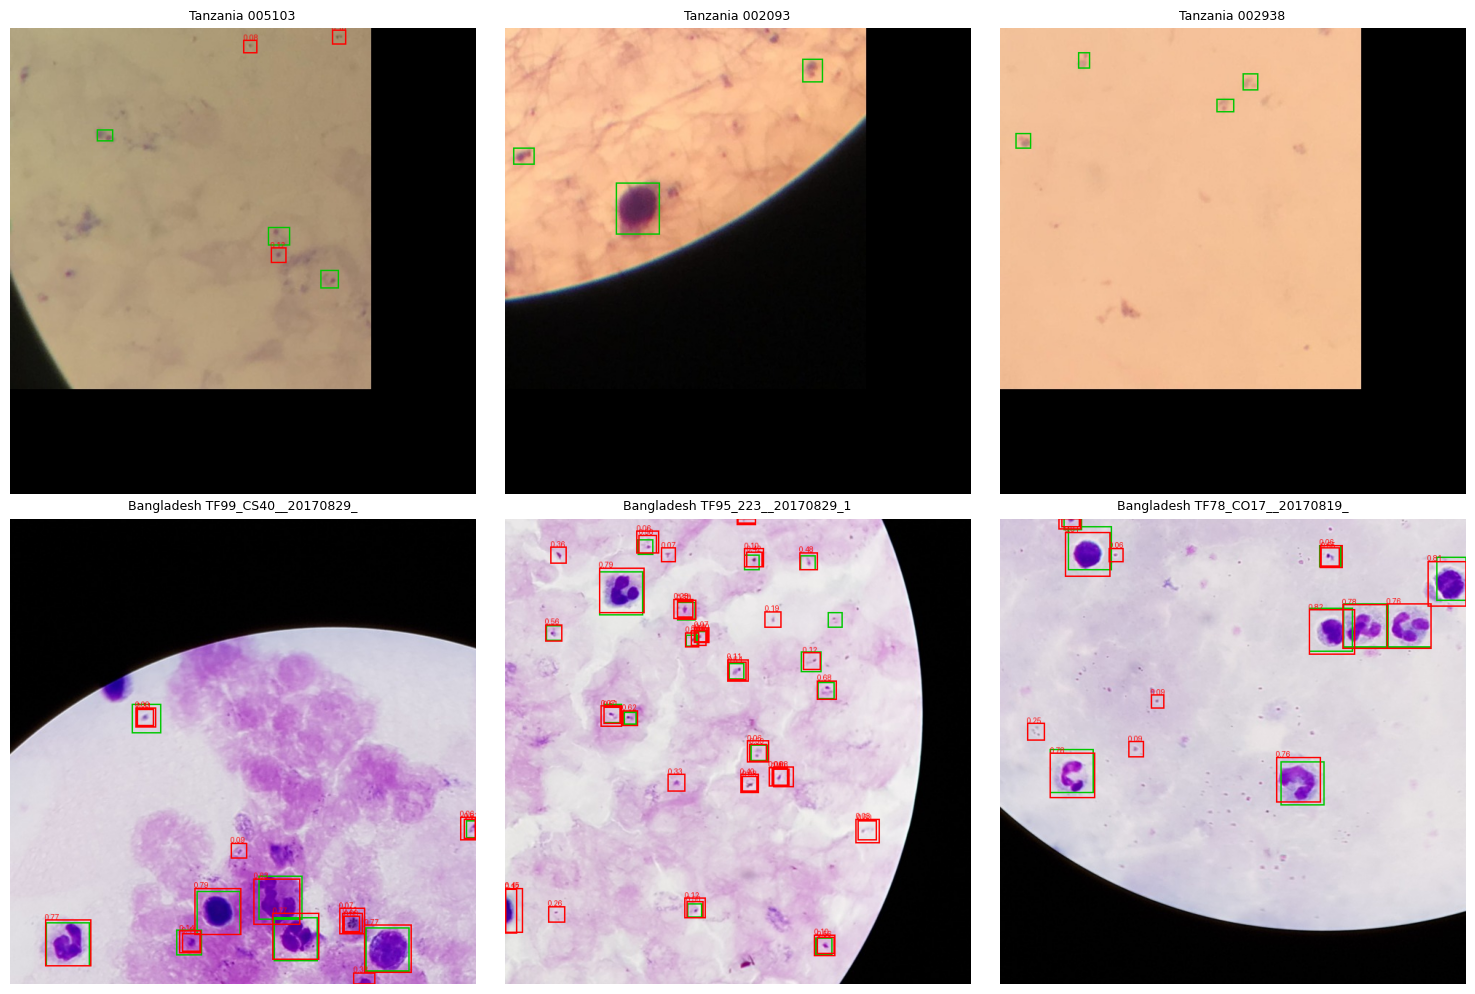

In [7]:
import random, matplotlib.pyplot as plt
from PIL import ImageDraw
random.seed(5)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
picks = random.sample(sorted((tz_dir / "test" / "images").glob("*.jpg")), 3)
bd_picks = random.sample(sorted((bd_dir / "test" / "images").glob("*.jpg")), 3)
for ax, p in zip(axes.flat, picks + bd_picks):
    im = Image.open(p).convert("RGB"); d = ImageDraw.Draw(im)
    for line in (p.parent.parent / "labels" / f"{p.stem}.txt").read_text().splitlines():
        c, x, y, w, h = map(float, line.split())
        d.rectangle([(x - w/2) * 640, (y - h/2) * 640, (x + w/2) * 640, (y + h/2) * 640], outline=(0, 200, 0), width=2)
    for (x1, y1, x2, y2), cf in zip(model.predict(str(p), imgsz=640, conf=0.05, verbose=False)[0].boxes.xyxy.cpu().numpy(),
                                    model.predict(str(p), imgsz=640, conf=0.05, verbose=False)[0].boxes.conf.cpu().numpy()):
        d.rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=2); d.text((x1, y1 - 10), f"{cf:.2f}", fill=(255, 0, 0))
    ax.imshow(im); ax.set_title(("Tanzania " if "tz_tiles" in str(p) else "Bangladesh ") + p.stem[:20], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [8]:
import cv2, shutil
def lab_px(p):
    im = cv2.imread(str(p)); m = im.mean(axis=2) > 40           
    return cv2.cvtColor(im, cv2.COLOR_BGR2LAB).astype(np.float32), m
random.seed(0)
ref = np.concatenate([(lambda L, m: L[m])(*lab_px(p)) for p in random.sample(sorted((bd_dir / "train" / "images").glob("*.jpg")), 300)])
bd_mu, bd_sd = ref.mean(0), ref.std(0)

random.seed(1)
SUB = random.sample(sorted((tz_dir / "test" / "images").glob("*.jpg")), 1000)
for name in ["tz_orig_sub", "tz_recolour_sub"]:
    for sub in ["images", "labels"]: (Path("/kaggle/working") / name / "test" / sub).mkdir(parents=True, exist_ok=True)
for p in SUB:
    L, m = lab_px(p)
    L[m] = (L[m] - L[m].mean(0)) / (L[m].std(0) + 1e-6) * bd_sd + bd_mu     
    cv2.imwrite(f"/kaggle/working/tz_recolour_sub/test/images/{p.name}",
                cv2.cvtColor(np.clip(L, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR))
    shutil.copy(p, f"/kaggle/working/tz_orig_sub/test/images/{p.name}")
    for name in ["tz_orig_sub", "tz_recolour_sub"]:
        shutil.copy(tz_dir / "test" / "labels" / f"{p.stem}.txt", f"/kaggle/working/{name}/test/labels/{p.stem}.txt")

out = {}
for name in ["tz_orig_sub", "tz_recolour_sub"]:
    y = f"/kaggle/working/{name}.yaml"
    yaml.safe_dump({"path": f"/kaggle/working/{name}", "train": "test/images", "val": "test/images", "test": "test/images",
                    "names": {0: "parasite", 1: "wbc"}}, open(y, "w"))
    m = model.val(data=y, split="test", imgsz=640, batch=32, device=0, plots=False, verbose=False)
    out[name] = {"parasite recall": m.box.r[0], "parasite mAP50": m.box.ap50[0], "wbc mAP50": m.box.ap50[1]}
print(pd.DataFrame(out).T.round(3))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 891.2±252.8 MB/s, size: 28.6 KB)
val: Scanning /kaggle/working/tz_orig_sub/test/labels... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.2Kit/s 0.8s0ss
val: New cache created: /kaggle/working/tz_orig_sub/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.5it/s 12.8s0.4s
                   all       1000       4492      0.397      0.141      0.132     0.0531
Speed: 0.7ms preprocess, 9.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1934.0±512.8 MB/s

In [9]:
gh_src = next(p for p in inp.rglob("gh_images") if p.is_dir())
GP = Path("/kaggle/working/gh_pad/test"); C = 2048
for sub in ["images", "labels"]: (GP / sub).mkdir(parents=True, exist_ok=True)
for p in sorted((gh_src / "test" / "images").glob("*.jpg")):
    im = Image.open(p).convert("RGB")
    s = min(1.0, C / max(im.size))                     
    if s < 1: im = im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR)
    canvas = Image.new("RGB", (C, C), (0, 0, 0)); canvas.paste(im, (0, 0)); canvas.save(GP / "images" / p.name, quality=92)
    out = []
    for line in (gh_src / "test" / "labels" / f"{p.stem}.txt").read_text().splitlines():
        c, x, y, w, h = map(float, line.split())
        out.append(f"{int(c)} {x * im.width / C:.6f} {y * im.height / C:.6f} {w * im.width / C:.6f} {h * im.height / C:.6f}")
    (GP / "labels" / f"{p.stem}.txt").write_text("\n".join(out))
yaml.safe_dump({"path": "/kaggle/working/gh_pad", "train": "test/images", "val": "test/images", "test": "test/images",
                "names": {0: "parasite", 1: "wbc"}}, open("/kaggle/working/gh.yaml", "w"))
print("Ghana padded images:", len(list((GP / "images").glob("*.jpg"))))

Ghana padded images: 3043


In [10]:
m = model.val(data="/kaggle/working/gh.yaml", split="test", imgsz=C, batch=4, device=0, plots=False, verbose=False)
print(f"Ghana: parasite precision {m.box.p[0]:.3f}  recall {m.box.r[0]:.3f}  mAP50 {m.box.ap50[0]:.3f} | wbc mAP50 {m.box.ap50[1]:.3f}")

rows = []
for r in model.predict(source=str(GP / "images"), imgsz=C, conf=0.05, max_det=3000, device=0, stream=True, verbose=False):
    k, cf = r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()
    rows.append((Path(r.path).stem, ((k == 0) & (cf >= T_PAR)).sum(), ((k == 1) & (cf >= 0.25)).sum()))
g = pd.DataFrame(rows, columns=["image", "pred_par", "pred_wbc"]).set_index("image")
for k, col in [(0, "parasite"), (1, "wbc")]:
    g[col] = [sum(1 for l in (GP / "labels" / f"{i}.txt").read_text().splitlines() if l.startswith(f"{k} ")) for i in g.index]
summarise(g.pred_par, g.parasite, "Ghana     ")
print(f"Ghana WBCs: labelled {g.wbc.sum()}, model found {g.pred_wbc.sum()}")
print(f"Ghana pooled density: labels {g.parasite.sum() / g.wbc.sum() * 8000:,.0f}/uL | model {g.pred_par.sum() / g.pred_wbc.sum() * 8000:,.0f}/uL")
g.to_csv("/kaggle/working/gh_per_image_pred.csv")

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3645.3±1298.2 MB/s, size: 281.0 KB)
val: Scanning /kaggle/working/gh_pad/test/labels... 3043 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3043/3043 944.5it/s 3.2s0.1s
val: New cache created: /kaggle/working/gh_pad/test/labels.cache
WARNING ⚠️ Dataset images contain up to 628 objects (test=628), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=628 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 761/761 2.0it/s 6:140.5ss
                   all       3043     377166      0.605      0.378      0.383      0.152
Speed: 7.0m